# Traffic Flow Optimization in a City Grid
### Using Dijkstra and A* Algorithms

**Course:** Design and Analysis of Algorithms

This notebook models a city as a weighted grid, finds the fastest route with Dijkstra and A*, simulates traffic congestion, and compares the algorithms before and after traffic changes.


## Checkpoint 1 — Imports and Configuration
Run this cell first and save the notebook checkpoint as **01-imports**.


In [3]:
import heapq
import random
import time
from statistics import median
import matplotlib.pyplot as plt

SEED = 7
SIZE = 30
MIN_WEIGHT = 1
MAX_WEIGHT = 9
START = (0, 0)
GOAL = (SIZE - 1, SIZE - 1)

print(f"Grid: {SIZE}x{SIZE} = {SIZE*SIZE} intersections")
print("Start:", START, "Goal:", GOAL)


Grid: 30x30 = 900 intersections
Start: (0, 0) Goal: (29, 29)


## Checkpoint 2 — Build the Weighted City Grid


In [22]:
def neighbors(node, size=SIZE):
    r, c = node
    for dr, dc in ((1,0),(-1,0),(0,1),(0,-1)):
        nr, nc = r + dr, c + dc
        if 0 <= nr < size and 0 <= nc < size:
            yield (nr, nc)

def build_grid(size=SIZE, seed=SEED):
    rng = random.Random(seed)
    graph = {}
    for r in range(size):
        for c in range(size):
            u = (r, c)
            graph[u] = {}
            for v in neighbors(u, size):
                graph[u][v] = rng.randint(MIN_WEIGHT, MAX_WEIGHT)
    return graph

grid = build_grid()
print("Weighted graph created successfully.")
print("Example:", START, "->", grid[START])


Weighted graph created successfully.
Example: (0, 0) -> {(1, 0): 6, (0, 1): 3}


## Checkpoint 3 — Visualize the City Grid


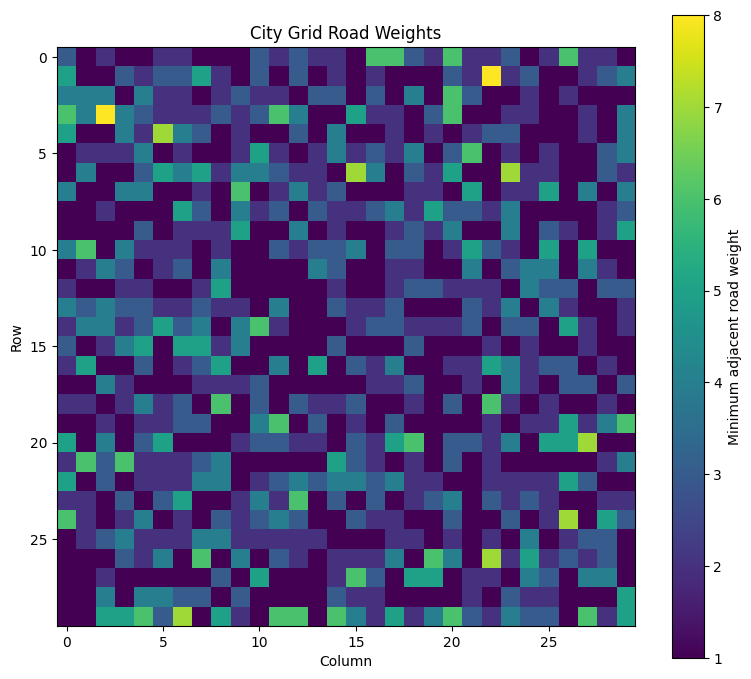

In [23]:
def show_grid_weights(graph, title="City Grid Road Weights"):
    matrix = [[0]*SIZE for _ in range(SIZE)]
    for (r,c), edges in graph.items():
        matrix[r][c] = min(edges.values()) if edges else 0
    plt.figure(figsize=(8,7))
    plt.imshow(matrix)
    plt.colorbar(label="Minimum adjacent road weight")
    plt.title(title)
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.tight_layout()
    plt.show()

show_grid_weights(grid)


## Checkpoint 4 — Dijkstra
Dijkstra explores the graph using the accumulated travel cost from the start node.


In [24]:
def dijkstra(graph, start, goal):
    dist = {node: float("inf") for node in graph}
    prev = {node: None for node in graph}

    dist[start] = 0
    pq = [(0, start)]
    expanded = set()

    while pq:
        cost, u = heapq.heappop(pq)

        if u in expanded:
            continue

        expanded.add(u)

        if u == goal:
            break

        for v, weight in graph[u].items():
            new_cost = cost + weight

            if new_cost < dist[v]:
                dist[v] = new_cost
                prev[v] = u
                heapq.heappush(pq, (new_cost, v))

    if dist[goal] == float("inf"):
        return [], float("inf"), len(expanded)

    path = []
    cur = goal

    while cur is not None:
        path.append(cur)
        cur = prev[cur]

    path.reverse()

    return path, dist[goal], len(expanded)
       


## Checkpoint 5 — A* with an Admissible Manhattan Heuristic
Because road weights are at least 1, Manhattan distance multiplied by the minimum road weight is a safe lower bound on remaining travel cost.


In [32]:
def heuristic(a, b):
    return (abs(a[0] - b[0]) + abs(a[1] - b[1])) * MIN_WEIGHT


def a_star(graph, start, goal):
    g = {node: float("inf") for node in graph}
    prev = {node: None for node in graph}

    g[start] = 0
    pq = [(heuristic(start, goal), 0, start)]
    expanded = set()

    while pq:
        f, cost, u = heapq.heappop(pq)

        if u in expanded:
            continue

        expanded.add(u)

        if u == goal:
            break

        for v, weight in graph[u].items():
            new_g = cost + weight

            if new_g < g[v]:
                g[v] = new_g
                prev[v] = u
                heapq.heappush(
                    pq,
                    (new_g + heuristic(v, goal), new_g, v)
                )

    if g[goal] == float("inf"):
        return [], float("inf"), len(expanded)

    path = []
    cur = goal

    while cur is not None:
        path.append(cur)
        cur = prev[cur]

    path.reverse()

    return path, g[goal], len(expanded)

In [33]:
path_a, cost_a, visited_a = a_star(grid, START, GOAL)

print("A* Results:")
print("Shortest path:", path_a)
print("Total cost:", cost_a)
print("Visited nodes:", visited_a)

A* Results:
Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (3, 4), (3, 5), (4, 5), (5, 5), (6, 5), (7, 5), (8, 5), (9, 5), (9, 6), (9, 7), (10, 7), (10, 8), (11, 8), (11, 9), (11, 10), (10, 10), (10, 11), (11, 11), (11, 12), (12, 12), (12, 13), (13, 13), (13, 14), (13, 15), (14, 15), (14, 16), (15, 16), (15, 17), (15, 18), (16, 18), (17, 18), (17, 19), (17, 20), (17, 21), (18, 21), (19, 21), (19, 22), (20, 22), (20, 23), (21, 23), (21, 24), (21, 25), (22, 25), (23, 25), (23, 26), (24, 26), (24, 27), (25, 27), (26, 27), (26, 28), (27, 28), (28, 28), (28, 29), (29, 29)]
Total cost: 166
Visited nodes: 900


In [41]:
path_d, cost_d, visited_d = dijkstra(grid, START, GOAL)

print("Dijkstra Results:")
print("Shortest path:", path_d)
print("Total cost:", cost_d)
print("Visited nodes:", visited_d)

Dijkstra Results:
Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (3, 4), (3, 5), (4, 5), (5, 5), (6, 5), (7, 5), (8, 5), (9, 5), (9, 6), (9, 7), (10, 7), (10, 8), (11, 8), (11, 9), (11, 10), (10, 10), (10, 11), (11, 11), (11, 12), (12, 12), (12, 13), (13, 13), (13, 14), (13, 15), (14, 15), (14, 16), (15, 16), (15, 17), (15, 18), (16, 18), (17, 18), (17, 19), (17, 20), (17, 21), (18, 21), (19, 21), (19, 22), (20, 22), (20, 23), (21, 23), (21, 24), (21, 25), (22, 25), (23, 25), (23, 26), (24, 26), (24, 27), (25, 27), (26, 27), (26, 28), (27, 28), (28, 28), (28, 29), (29, 29)]
Total cost: 166
Visited nodes: 900


## Checkpoint 6 — Compare Algorithms Before Traffic


In [42]:
d_path, d_cost, d_nodes = dijkstra(grid, START, GOAL)
a_path, a_cost, a_nodes = a_star(grid, START, GOAL)

print("BEFORE TRAFFIC")
print(f"Dijkstra: {d_cost} minutes | {len(d_path)-1} steps | {d_nodes} expanded nodes")
print(f"A*:       {a_cost} minutes | {len(a_path)-1} steps | {a_nodes} expanded nodes")
print("Same optimal cost:", d_cost == a_cost)


BEFORE TRAFFIC
Dijkstra: 166 minutes | 60 steps | 900 expanded nodes
A*:       166 minutes | 60 steps | 900 expanded nodes
Same optimal cost: True


## Checkpoint 7 — Simulate Dynamic Traffic
Traffic is simulated by increasing the cost of roads crossing a central congestion zone.


In [44]:
import copy

def add_traffic(graph, factor=5, rows=None):
    updated = copy.deepcopy(graph)
    if rows is None:
        rows = [SIZE//2 - 1, SIZE//2]
    for r in rows:
        for c in range(SIZE-1):
            u, v = (r,c), (r,c+1)
            updated[u][v] *= factor
            updated[v][u] *= factor
    return updated

traffic_grid = add_traffic(grid)
print("Traffic congestion added to rows:", [SIZE//2 - 1, SIZE//2])


Traffic congestion added to rows: [14, 15]


In [45]:
print("Original cost:", grid[(14, 0)][(14, 1)])
print("Traffic cost:", traffic_grid[(14, 0)][(14, 1)])

Original cost: 2
Traffic cost: 10


## Checkpoint 8 — Compare Before and After Traffic


In [46]:
before_path, before_cost, _ = dijkstra(grid, START, GOAL)
after_path, after_cost, _ = dijkstra(traffic_grid, START, GOAL)

print("Travel time before traffic:", before_cost, "minutes")
print("Travel time after traffic: ", after_cost, "minutes")
print("Change:", after_cost - before_cost, "minutes")
print("Route changed:", before_path != after_path)


Travel time before traffic: 166 minutes
Travel time after traffic:  169 minutes
Change: 3 minutes
Route changed: True


## Checkpoint 9 — Final Dijkstra vs A* After Traffic


In [38]:
d2_path, d2_cost, d2_nodes = dijkstra(traffic_grid, START, GOAL)
a2_path, a2_cost, a2_nodes = a_star(traffic_grid, START, GOAL)

print("AFTER TRAFFIC")
print(f"Dijkstra: {d2_cost} minutes | {len(d2_path)-1} steps | {d2_nodes} expanded nodes")
print(f"A*:       {a2_cost} minutes | {len(a2_path)-1} steps | {a2_nodes} expanded nodes")
print("Same optimal cost:", d2_cost == a2_cost)

if a2_nodes < d2_nodes:
    print("A* expanded fewer nodes in this experiment.")
elif a2_nodes > d2_nodes:
    print("Dijkstra expanded fewer nodes in this experiment.")
else:
    print("Both algorithms expanded the same number of nodes in this experiment.")


AFTER TRAFFIC
Dijkstra: 169 minutes | 62 steps | 900 expanded nodes
A*:       169 minutes | 62 steps | 900 expanded nodes
Same optimal cost: True
Both algorithms expanded the same number of nodes in this experiment.


## Checkpoint 10 — Visualize the Routes and Results


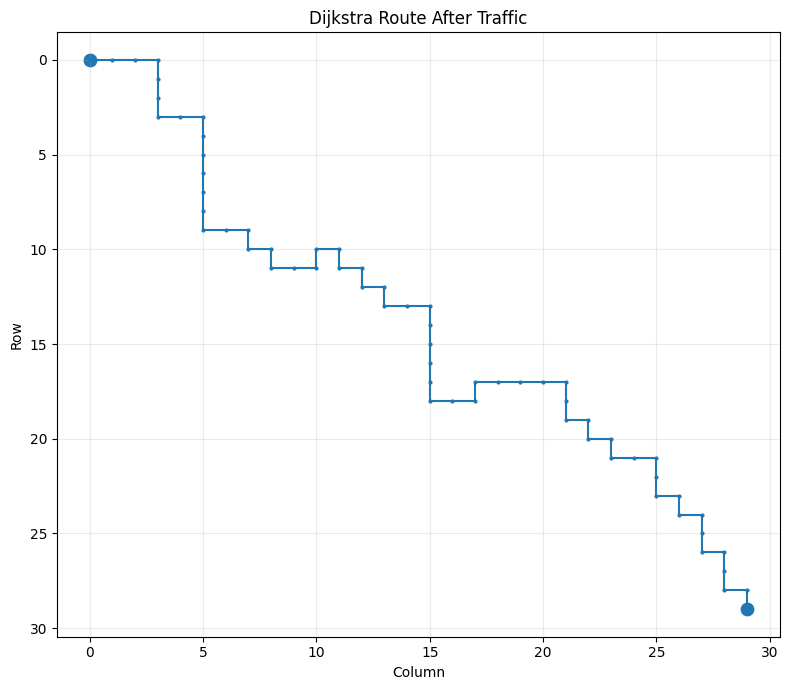

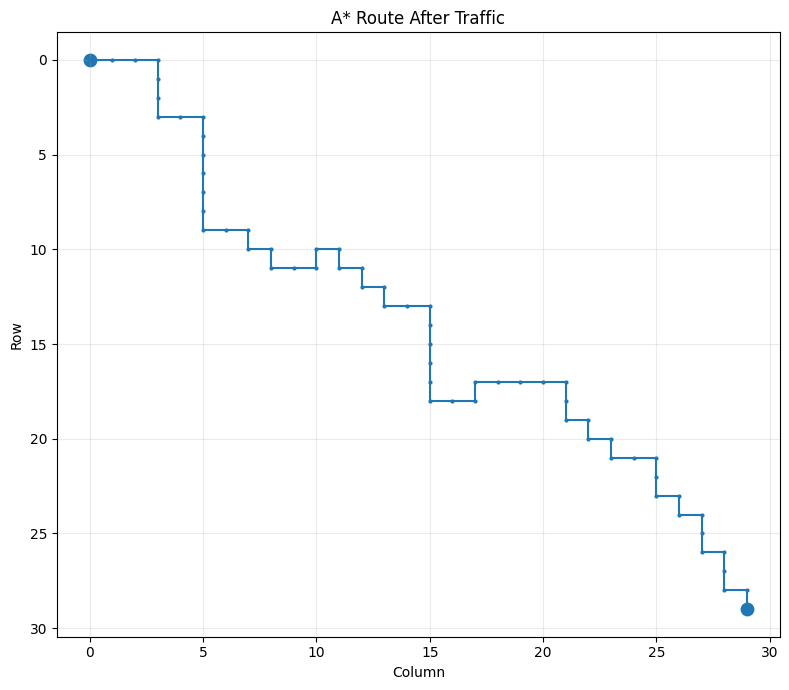

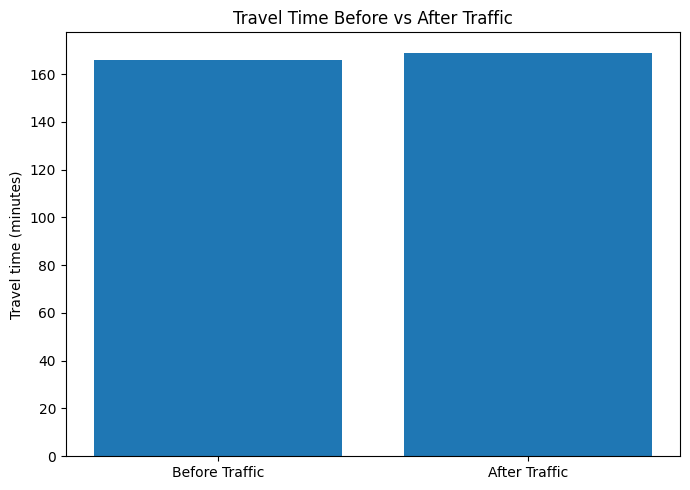

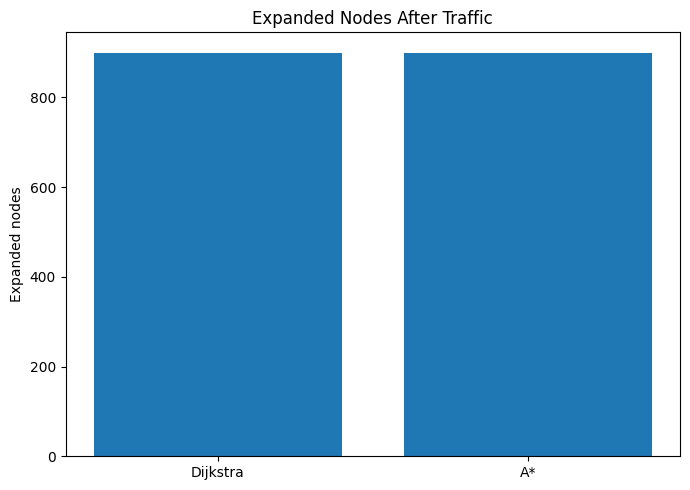

In [39]:
def plot_route(path, title):
    plt.figure(figsize=(8,7))
    xs = [c for r,c in path]
    ys = [r for r,c in path]
    plt.plot(xs, ys, marker="o", markersize=2)
    plt.scatter([START[1], GOAL[1]], [START[0], GOAL[0]], s=80)
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.25)
    plt.title(title)
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.tight_layout()
    plt.show()

plot_route(d2_path, "Dijkstra Route After Traffic")
plot_route(a2_path, "A* Route After Traffic")

plt.figure(figsize=(7,5))
plt.bar(["Before Traffic","After Traffic"], [before_cost, after_cost])
plt.ylabel("Travel time (minutes)")
plt.title("Travel Time Before vs After Traffic")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.bar(["Dijkstra","A*"], [d2_nodes, a2_nodes])
plt.ylabel("Expanded nodes")
plt.title("Expanded Nodes After Traffic")
plt.tight_layout()
plt.show()


## Checkpoint 11 — Runtime Performance
We use the median of repeated runs so one unusually slow run does not dominate the comparison.


Dijkstra median runtime: 0.00223640 seconds
A* median runtime:       0.00234914 seconds


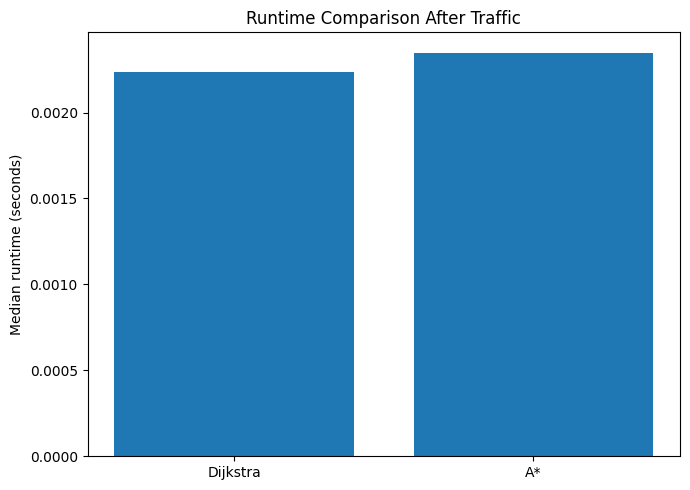

In [40]:
def median_runtime(function, graph, start, goal, repeats=30):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        function(graph, start, goal)
        times.append(time.perf_counter() - t0)
    return median(times)

d_time = median_runtime(dijkstra, traffic_grid, START, GOAL)
a_time = median_runtime(a_star, traffic_grid, START, GOAL)

print(f"Dijkstra median runtime: {d_time:.8f} seconds")
print(f"A* median runtime:       {a_time:.8f} seconds")

plt.figure(figsize=(7,5))
plt.bar(["Dijkstra","A*"], [d_time, a_time])
plt.ylabel("Median runtime (seconds)")
plt.title("Runtime Comparison After Traffic")
plt.tight_layout()
plt.show()


## Checkpoint 12 — Complexity and Conclusion

### Complexity
- **Dijkstra:** with a binary-heap priority queue, typical complexity is `O((V + E) log V)`.
- **A\*:** with a binary-heap priority queue, worst-case complexity is also `O((V + E) log V)` for this graph-search implementation.
- Both algorithms require graph/search structures proportional to graph size.

### Conclusion
The project models a city as a weighted grid where intersections are nodes and roads have travel-time costs. Dijkstra and A* are used to find an optimal route. Traffic congestion is simulated by increasing selected road weights, allowing us to observe how the optimal route and travel time change. The experiment compares optimal cost, expanded nodes, and runtime. A* is guided toward the destination by a Manhattan-distance heuristic, while Dijkstra has no heuristic guidance. The results are experiment-dependent: A* should not be claimed to always outperform Dijkstra.
